In [1]:
import pandas as pd

# 1. Load the CSV file
# If running in Google Colab, you can upload your file using files.upload() first,
# or mount your Google Drive.
df = pd.read_csv("server_monitoring_data.csv")

# Define the metrics to check for anomalies
metrics = ["cpu_usage_pct", "memory_usage_pct", "response_time_ms"]

# Initialize a boolean mask to track anomaly rows across all metrics
anomaly_mask = pd.Series(False, index=df.index)

# 2 & 3. Calculate server-specific stats and flag values > 3 std above the mean
for col in metrics:
  # Calculate mean and standard deviation grouped by server_name
  mean_series = df.groupby("server_name")[col].transform("mean")
  std_series = df.groupby("server_name")[col].transform("std")

  # Flag rows where the metric is strictly more than 3 standard deviations above the mean
  col_anomaly = (df[col] - mean_series) > (3 * std_series)

  # Combine with overall anomaly mask (True if anomaly in any metric)
  anomaly_mask = anomaly_mask | col_anomaly

# Create a filtered DataFrame containing only the anomaly rows
anomalies_df = df[anomaly_mask].copy()

# 4. Print the summary
print(f"Total anomalies found: {len(anomalies_df)}")
print("\nAnomaly breakdown per server:")
print(anomalies_df["server_name"].value_counts())

# 5. Save the flagged anomaly rows to a new CSV file
anomalies_df.to_csv("detected_anomalies.csv", index=False)
print("\nSaved flagged anomalies to 'detected_anomalies.csv'")

Total anomalies found: 412

Anomaly breakdown per server:
server_name
DB-PROD-02      76
FILE-PROD-01    61
APP-PROD-02     55
DB-PROD-01      51
APP-PROD-01     45
AUTH-PROD-01    43
WEB-PROD-02     41
WEB-PROD-01     40
Name: count, dtype: int64

Saved flagged anomalies to 'detected_anomalies.csv'


Total anomalies found: 412

Anomaly breakdown per server:
server_name
DB-PROD-02      76
FILE-PROD-01    61
APP-PROD-02     55
DB-PROD-01      51
APP-PROD-01     45
AUTH-PROD-01    43
WEB-PROD-02     41
WEB-PROD-01     40
Name: count, dtype: int64

Saved flagged anomalies to 'detected_anomalies.csv'


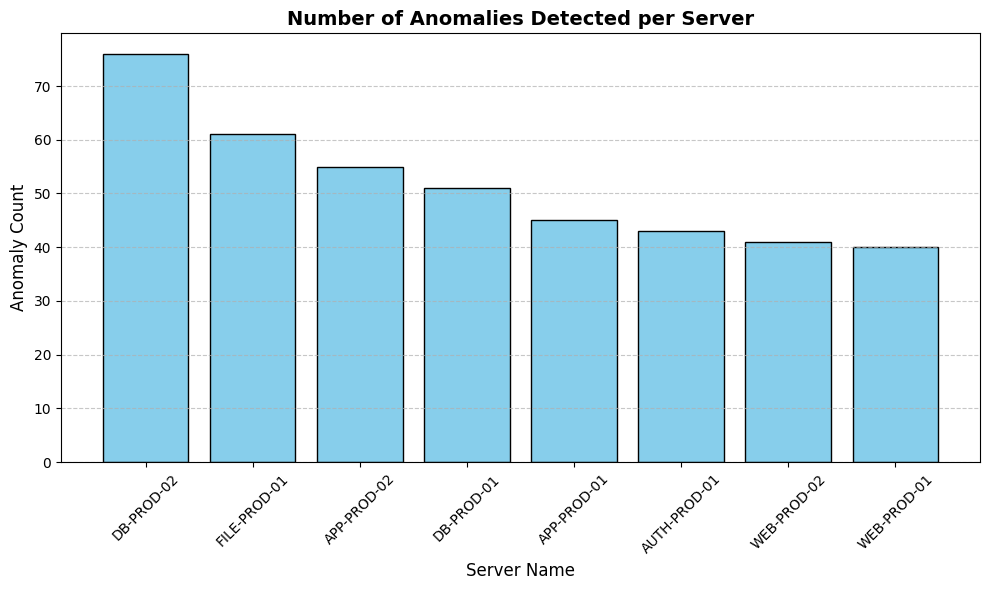


Server with the most anomalies: DB-PROD-02


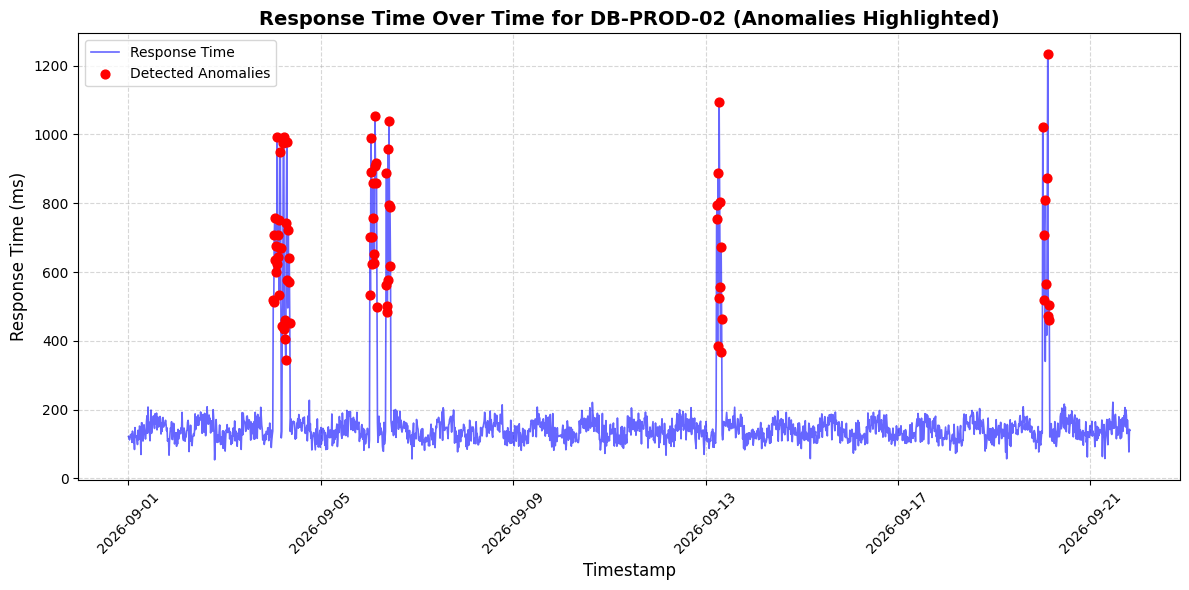

Charts saved successfully as 'anomalies_by_server.png' and 'response_time_anomalies.png'.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the CSV file and parse timestamps as datetime objects
df = pd.read_csv("server_monitoring_data.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Define the metrics to check for anomalies
metrics = ["cpu_usage_pct", "memory_usage_pct", "response_time_ms"]

# Initialize a boolean mask to track anomaly rows across all metrics
anomaly_mask = pd.Series(False, index=df.index)

# 2 & 3. Calculate server-specific stats and flag values > 3 std above the mean
for col in metrics:
  mean_series = df.groupby("server_name")[col].transform("mean")
  std_series = df.groupby("server_name")[col].transform("std")
  col_anomaly = (df[col] - mean_series) > (3 * std_series)
  anomaly_mask = anomaly_mask | col_anomaly

# Create a filtered DataFrame containing only the anomaly rows
anomalies_df = df[anomaly_mask].copy()

# 4. Print the summary
print(f"Total anomalies found: {len(anomalies_df)}")
print("\nAnomaly breakdown per server:")
print(anomalies_df["server_name"].value_counts())

# 5. Save the flagged anomaly rows to a new CSV file
anomalies_df.to_csv("detected_anomalies.csv", index=False)
print("\nSaved flagged anomalies to 'detected_anomalies.csv'")


# ==========================================
# NEW VISUALIZATION CODE
# ==========================================

# --- Chart 1: Bar chart of anomalies per server ---
# Get counts per server (including servers with 0 if necessary, but value_counts works well here)
server_anomaly_counts = anomalies_df["server_name"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(
    server_anomaly_counts.index,
    server_anomaly_counts.values,
    color="skyblue",
    edgecolor="black",
)
plt.title("Number of Anomalies Detected per Server", fontsize=14, fontweight="bold")
plt.xlabel("Server Name", fontsize=12)
plt.ylabel("Anomaly Count", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

# Save Chart 1
plt.savefig("anomalies_by_server.png", dpi=300)
plt.show()

# --- Chart 2: Response time over time for the server with the most anomalies ---
# Identify the server with the highest number of anomalies
top_server = server_anomaly_counts.idxmax()
print(f"\nServer with the most anomalies: {top_server}")

# Filter data for this specific server
server_all_data = df[df["server_name"] == top_server].sort_values("timestamp")
server_anomaly_data = anomalies_df[
    anomalies_df["server_name"] == top_server
].sort_values("timestamp")

plt.figure(figsize=(12, 6))
# Plot the baseline response time trend
plt.plot(
    server_all_data["timestamp"],
    server_all_data["response_time_ms"],
    label="Response Time",
    color="blue",
    alpha=0.6,
    linewidth=1.2,
)
# Highlight the anomaly points in red
plt.scatter(
    server_anomaly_data["timestamp"],
    server_anomaly_data["response_time_ms"],
    label="Detected Anomalies",
    color="red",
    s=40,
    zorder=5,
)

plt.title(
    f"Response Time Over Time for {top_server} (Anomalies Highlighted)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Timestamp", fontsize=12)
plt.ylabel("Response Time (ms)", fontsize=12)
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Save Chart 2
plt.savefig("response_time_anomalies.png", dpi=300)
plt.show()
print(
    "Charts saved successfully as 'anomalies_by_server.png' and"
    " 'response_time_anomalies.png'."
)